# Imports

## Importing Libraries

In [1]:
# Import libraries, silence warnings, and define native Stata-exact svyset and Rao-Scott functions.
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.weightstats import DescrStatsW
from pandas.io.stata import StataReader

def svy_prop_stata_centered(df, y_col, w_col, strata_col, psu_col, domain_col):
    sub = df[[y_col, w_col, strata_col, psu_col, domain_col]].dropna().copy()
    y = sub[y_col].to_numpy(dtype=float)
    w = sub[w_col].to_numpy(dtype=float)
    strata = sub[strata_col].to_numpy()
    psu = sub[psu_col].to_numpy()
    dom = sub[domain_col].to_numpy()

    unique_strata = np.unique(strata)
    L = len(unique_strata)
    total_psus = sum(len(np.unique(psu[strata == h])) for h in unique_strata)
    df_design = max(total_psus - L, 1)
    t_crit = stats.t.ppf(0.975, df=df_design)

    results = {}
    for d in np.unique(dom):
        d_mask = (dom == d).astype(float)
        W_d = np.sum(w * d_mask)
        p_hat = np.sum(w * d_mask * y) / W_d
        z = w * d_mask * (y - p_hat) / W_d

        psu_totals_by_stratum = []
        all_psu_totals = []
        for h in unique_strata:
            h_mask = (strata == h)
            psus_h = np.unique(psu[h_mask])
            z_h = np.array([np.sum(z[h_mask & (psu == i)]) for i in psus_h])
            psu_totals_by_stratum.append(z_h)
            all_psu_totals.extend(z_h)

        z_bar_grand = np.mean(all_psu_totals)
        var_p = 0.0
        for z_h in psu_totals_by_stratum:
            n_h = len(z_h)
            if n_h > 1:
                var_p += (n_h / (n_h - 1.0)) * np.sum((z_h - np.mean(z_h)) ** 2)
            elif n_h == 1:
                var_p += (z_h[0] - z_bar_grand) ** 2

        se_p = np.sqrt(var_p)
        if 0 < p_hat < 1 and se_p > 0:
            logit_p = np.log(p_hat / (1.0 - p_hat))
            se_logit = se_p / (p_hat * (1.0 - p_hat))
            lci = 1.0 / (1.0 + np.exp(-(logit_p - t_crit * se_logit)))
            uci = 1.0 / (1.0 + np.exp(-(logit_p + t_crit * se_logit)))
        else:
            lci, uci = p_hat, p_hat

        results[d] = {'est': p_hat * 100, 'se': se_p, 'lci': lci * 100, 'uci': uci * 100}

    return pd.DataFrame.from_dict(results, orient='index'), df_design

def rao_scott_chisquare(df, y_col, w_col, strata_col, psu_col, domain_col):
    sub = df[[y_col, w_col, strata_col, psu_col, domain_col]].dropna().copy()
    n = len(sub)
    w_tab = pd.crosstab(sub[domain_col], sub[y_col], values=sub[w_col], aggfunc='sum').fillna(0)
    w_scaled = w_tab * (n / w_tab.to_numpy().sum())
    chi2_p, _, dof, _ = stats.chi2_contingency(w_scaled, correction=False)
    est_df, df_design = svy_prop_stata_centered(sub, y_col, w_col, strata_col, psu_col, domain_col)
    p_d = est_df['est'].to_numpy() / 100.0
    var_d = est_df['se'].to_numpy() ** 2
    n_d = w_scaled.sum(axis=1).to_numpy()
    valid = (p_d > 0) & (p_d < 1) & (n_d > 0)
    deff = np.mean((var_d[valid] * n_d[valid]) / (p_d[valid] * (1.0 - p_d[valid]))) if np.any(valid) else 1.0
    f_stat = (chi2_p / dof) / max(deff, 1e-6)
    p_val = 1.0 - stats.f.cdf(f_stat, dof, df_design * dof)
    return round(chi2_p, 4), round(f_stat, 4), int(dof), round(p_val, 4)

## Load and add survey weights

In [2]:
# Load the Stata dataset, extract variable labels, and drop missing survey design or outcome records.
data = pd.read_stata("MICS-child-ISRC.dta", convert_categoricals=False)
stata_file = StataReader("MICS-child-ISRC.dta")
variable_labels = stata_file.variable_labels()
survey_cols = ['hh1', 'chweight', 'strata', 'severe_wasting']
df_clean = data.dropna(subset=survey_cols).copy()
df_clean = df_clean[df_clean['chweight'] > 0].reset_index(drop=True)
variable_labels

{'hh1': 'Cluster number',
 'hh2': 'Household number',
 'ln': 'Line number',
 'ub2': 'Age of child in completed years',
 'chweight': "Children under 5's sample weight",
 'hh7a': 'District',
 'wb4': 'Age of mother/caretaker',
 'cm11': 'Total number of live births (children ever born)',
 'whz2': 'Weight for height z-score WHO',
 'strata': 'Sampling stratum (area x division)',
 'child_id': 'Unique child ID (cluster-household-line number)',
 'mother_id': 'Unique mother/caretaker ID (cluster-household-mother line number)',
 'hh_id': 'Unique household ID (cluster-household number)',
 'bd9': 'Times child ate solid/semi-solid food yesterday (7 = seven or more)',
 'diarrhoea_2w': 'Child had diarrhoea in last 2 weeks',
 'cough_2w': 'Child had cough in last 2 weeks',
 'breathing_2w': 'Child had difficulty breathing in last 2 weeks',
 'severe_wasting': 'Severe wasting (WHO WHZ < -3)',
 'mod_wasting': 'Moderate wasting (WHO -3 <= WHZ < -2)',
 'any_wasting': 'Any wasting (WHO WHZ < -2)',
 'wast_cat':

In [3]:
df_clean.shape

(22311, 49)

In [4]:
dropped_cols = ['whz2', 'mod_wasting', 'any_wasting', 'wast_cat']
try:
    df_clean = df_clean.drop(columns  = dropped_cols).copy()
except:
    print('Already Dropped!')
df_clean.shape

(22311, 45)

# Extended Exploratory Data Analysis

Added after data preparation and before the formal tests. Everything here is **descriptive**: it checks data quality, the survey design, the outcome definition, and the patterns that motivate the models below. Prevalences use the survey design (`hh1` / `strata` / `chweight`) via the `svy_prop_stata_centered` helper defined in the imports section.

Sections: (1) setup, (2) missingness, (3) outcome definition, (4) survey-design diagnostics, (5) age and sex, (6) geography, (7) household and maternal profile, (8) illness and age confounding, (9) predictor overlap, (10) infants 0-1 feeding and ANC, (11) data-validity checks, (12) summary.

## 1. Setup

In [5]:
# Plotting setup and a helper that returns design-based weighted prevalence (%) with 95% CI per group.
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

def prev_by(df, col, y="severe_wasting"):
    """Weighted prevalence (%) of `y` by levels of `col`, Taylor-linearized logit 95% CI, plus unweighted n and cases."""
    sub = df[[y, "chweight", "strata", "hh1", col]].dropna()
    est, _ = svy_prop_stata_centered(sub, y, "chweight", "strata", "hh1", col)
    est = est.copy()
    est["n"] = sub.groupby(col).size()
    est["cases"] = sub.groupby(col)[y].sum()
    return est

# Human-readable value labels from the Stata file.
_r = StataReader("MICS-child-ISRC.dta"); _r.read(); _vl = _r.value_labels()
_map = {"female": "sexlab", "urban": "arealab", "division": "division", "wealth": "wealthlab", "edu_level": "edulab",
        "parity_cat": "paritylab", "mage_cat": "magelab", "bf_status": "bflab", "anc_cat": "anccat", "fuel_cat": "fuelcat",
        "water_cat": "watercat", "toilet_cat": "toiletcat", "mother_married": "marlab"}
def lab(var, val):
    key = _map.get(var, "yn" if var in ("diarrhoea_2w", "cough_2w", "breathing_2w", "any_illness", "electricity", "insured") else None)
    try:
        return _vl[key][int(val)] if key else str(val)
    except Exception:
        return str(val)
print("Rows:", len(df_clean), "| PSUs:", df_clean.hh1.nunique(), "| strata:", df_clean.strata.nunique(), "| districts:", df_clean.hh7a.nunique())

Rows: 22311 | PSUs: 3144 | strata: 16 | districts: 67


## 2. Missingness (which gaps are structural?)

                                                                  label  missing_n  missing_pct  missing_pct_age0_1  missing_pct_age2_4
bd9             Times child ate solid/semi-solid food yesterday (7 = se      15783        70.74               26.55              100.00
anc_cat                    ANC visits category (children aged 0-1 only)      13513        60.57                1.01              100.00
fvs               Food variety score (food items eaten yesterday, 0-18)      13512        60.56                1.00              100.00
dds             Dietary diversity score (food groups eaten yesterday, 0      13496        60.49                0.82              100.00
fg_ofv             Ate other fruit or vegetables yesterday (bd8f, bd8h)      13448        60.28                0.28              100.00
fg_dairy             Had dairy yesterday (bd7b, bd7c, bd7d, bd8a, bd8o)      13445        60.26                0.25              100.00
fg_flesh             Ate flesh foods yesterday (

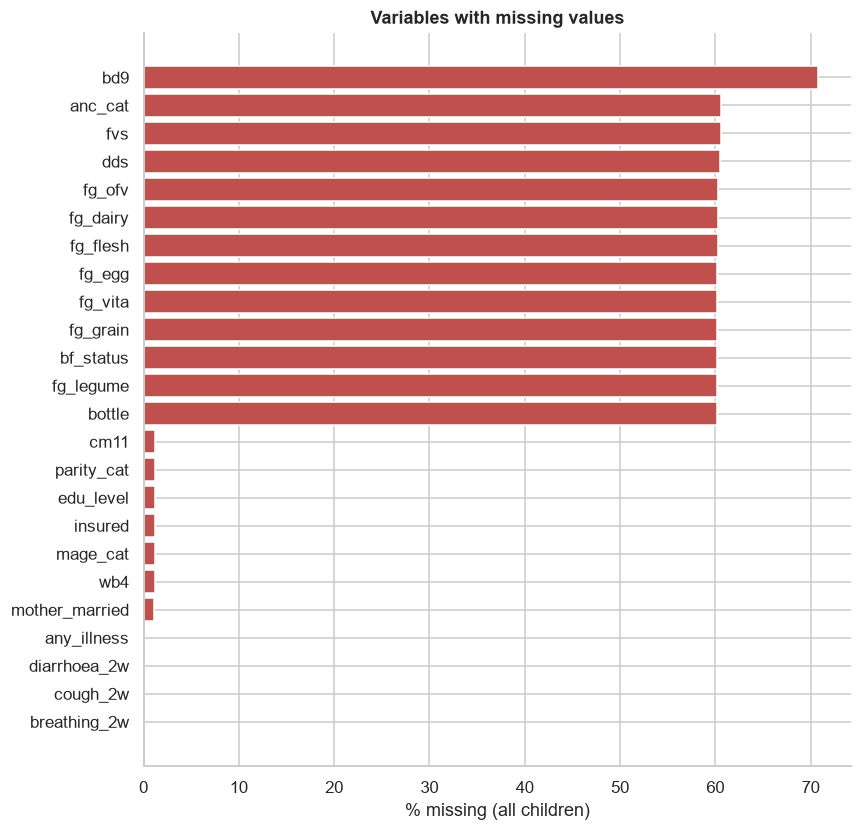

In [6]:
# Missingness overall and within each age group: infant-only variables are empty by design for ages 2-4.
cols = [c for c in df_clean.columns if c not in ("hh1", "hh2", "ln", "child_id", "mother_id", "hh_id", "chweight", "strata")]
m = pd.DataFrame({
    "label": [str(variable_labels.get(c, ""))[:55] for c in cols],
    "missing_n": df_clean[cols].isna().sum().values,
    "missing_pct": (df_clean[cols].isna().mean() * 100).round(2).values,
    "missing_pct_age0_1": (df_clean.loc[df_clean.young == 1, cols].isna().mean() * 100).round(2).values,
    "missing_pct_age2_4": (df_clean.loc[df_clean.young == 0, cols].isna().mean() * 100).round(2).values,
}, index=cols)
m = m[m.missing_n > 0].sort_values("missing_pct", ascending=False)
print(m.to_string())
fig, ax = plt.subplots(figsize=(8, 0.28 * len(m) + 1))
ax.barh(m.index[::-1], m.missing_pct[::-1], color="#c0504d")
ax.set_xlabel("% missing (all children)"); ax.set_title("Variables with missing values")
plt.tight_layout(); plt.show()

In [7]:
# Within the children the question applies to (age 0-1), how complete are the infant-only variables?
inf_vars = ["dds", "fvs", "bd9", "fg_grain", "fg_flesh", "bf_status", "bottle", "anc_cat"]
print((df_clean.loc[df_clean.young == 1, inf_vars].isna().mean() * 100).round(2).rename("missing % (age 0-1 only)").to_string())
print("\nChildren with ANY missing core-model predictor:",
      int(df_clean[["ub2","female","diarrhoea_2w","cough_2w","breathing_2w","edu_level","mage_cat","parity_cat","water_cat","toilet_cat","fuel_cat","urban","wealth","division"]].isna().any(axis=1).sum()),
      "of", len(df_clean))

dds           0.82
fvs           1.00
bd9          26.55
fg_grain      0.07
fg_flesh      0.16
bf_status     0.03
bottle        0.02
anc_cat       1.01

Children with ANY missing core-model predictor: 294 of 22311


## 3. Outcome definition and distribution

severe_wasting vs WHZ band (should be WHZ < -3 exactly):
whz2            WHZ < -3  -3 <= WHZ < -2  WHZ >= -2
severe_wasting                                     
0                      0            2353      19406
1                    552               0          0

WHZ range among severe cases: -4.96 to -3.01


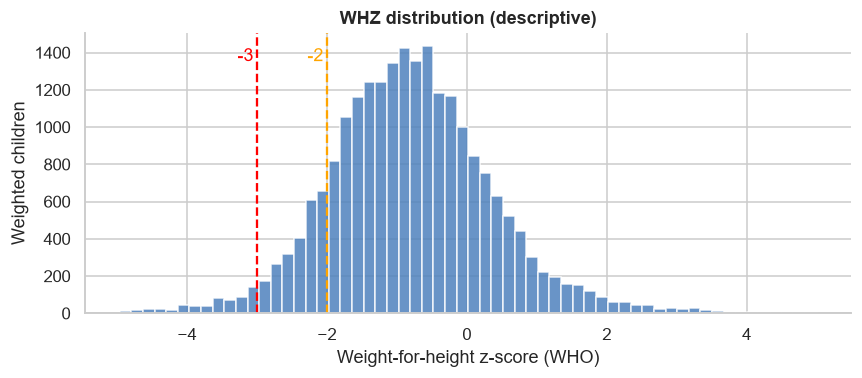


Severe wasting: unweighted 2.47% | weighted 2.52% (95% CI 2.29-2.77) | 552 cases / 22311 children


In [8]:
# Verify the outcome coding against the (descriptive-only) weight-for-height z-score kept in the raw file.
z = data.loc[df_clean.index if False else data.index, ["whz2", "severe_wasting", "wast_cat"]]
print("severe_wasting vs WHZ band (should be WHZ < -3 exactly):")
print(pd.crosstab(z.severe_wasting, pd.cut(z.whz2, [-np.inf, -3, -2, np.inf], right=False,
                  labels=["WHZ < -3", "-3 <= WHZ < -2", "WHZ >= -2"])))
print("\nWHZ range among severe cases:", z.loc[z.severe_wasting == 1, "whz2"].min(), "to", z.loc[z.severe_wasting == 1, "whz2"].max())
# Weighted WHZ distribution with cut-offs (whz2 is NOT used as a predictor anywhere).
w = data.loc[data.chweight > 0]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(w.whz2, bins=60, weights=w.chweight, color="#4f81bd", alpha=.85)
for x, c in [(-2, "orange"), (-3, "red")]:
    ax.axvline(x, color=c, ls="--"); ax.text(x - .05, ax.get_ylim()[1] * .9, f"{x}", color=c, ha="right")
ax.set_xlabel("Weight-for-height z-score (WHO)"); ax.set_ylabel("Weighted children"); ax.set_title("WHZ distribution (descriptive)")
plt.tight_layout(); plt.show()
# Prevalence of the three wasting endpoints.
p = prev_by(df_clean.assign(all_=1), "all_")
print("\nSevere wasting: unweighted %.2f%% | weighted %.2f%% (95%% CI %.2f-%.2f) | %d cases / %d children" % (
    df_clean.severe_wasting.mean() * 100, p.est.iloc[0], p.lci.iloc[0], p.uci.iloc[0], p.cases.iloc[0], p.n.iloc[0]))

## 4. Survey-design diagnostics

Weights: min 0.061  median 0.891  max 3.871  max/min 63.0
Kish effective n from weights alone: 16,412 of 22,311 (design effect from weighting = 1.36)
Children per PSU: mean 7.1, range 1-20 | PSUs per stratum: 33-451 (single-PSU strata: 0)
PSUs with at least one severe case: 15.7%  | max cases in a PSU: 3
Design SE 0.121 pp vs SRS SE 0.105 pp -> DEFF = 1.34, design df = 3128


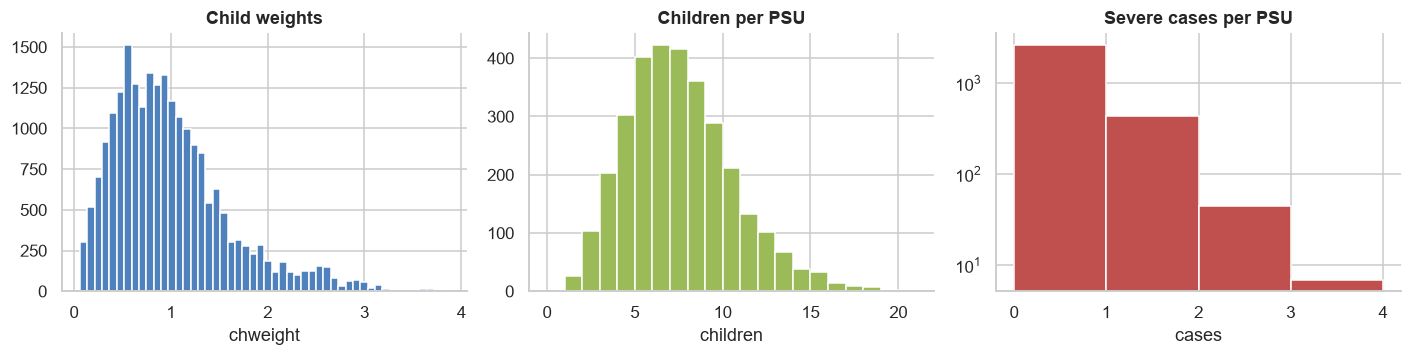

In [9]:
# Weights, cluster sizes, and the loss of precision caused by weighting and clustering.
wts = df_clean.chweight
n_eff_w = wts.sum() ** 2 / (wts ** 2).sum()
deff_w = len(wts) / n_eff_w
print(f"Weights: min {wts.min():.3f}  median {wts.median():.3f}  max {wts.max():.3f}  max/min {wts.max()/wts.min():.1f}")
print(f"Kish effective n from weights alone: {n_eff_w:,.0f} of {len(wts):,} (design effect from weighting = {deff_w:.2f})")
per_psu = df_clean.groupby("hh1").agg(n=("severe_wasting", "size"), cases=("severe_wasting", "sum"))
per_str = df_clean.groupby("strata").hh1.nunique()
print(f"Children per PSU: mean {per_psu.n.mean():.1f}, range {per_psu.n.min()}-{per_psu.n.max()} | PSUs per stratum: {per_str.min()}-{per_str.max()} (single-PSU strata: {(per_str==1).sum()})")
print(f"PSUs with at least one severe case: {(per_psu.cases>0).mean()*100:.1f}%  | max cases in a PSU: {per_psu.cases.max()}")

# Overall design effect for the prevalence estimate: design-based variance vs simple random sampling.
sub = df_clean.assign(all_=1)
est, dfd = svy_prop_stata_centered(sub, "severe_wasting", "chweight", "strata", "hh1", "all_")
p = est.est.iloc[0] / 100; se_design = est.se.iloc[0]; se_srs = np.sqrt(p * (1 - p) / len(df_clean))
print(f"Design SE {se_design*100:.3f} pp vs SRS SE {se_srs*100:.3f} pp -> DEFF = {(se_design/se_srs)**2:.2f}, design df = {dfd}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(wts, bins=50, color="#4f81bd"); ax[0].set_title("Child weights"); ax[0].set_xlabel("chweight")
ax[1].hist(per_psu.n, bins=range(0, 22), color="#9bbb59"); ax[1].set_title("Children per PSU"); ax[1].set_xlabel("children")
ax[2].hist(per_psu.cases, bins=range(0, int(per_psu.cases.max()) + 2), color="#c0504d"); ax[2].set_title("Severe cases per PSU"); ax[2].set_xlabel("cases"); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()

In [10]:
# Is clustering of cases real? Compare the observed spread of PSU case counts with what a binomial (no clustering) would give.
from scipy import stats as _st
p0 = df_clean.severe_wasting.mean()
exp_var = (per_psu.n * p0 * (1 - p0)).sum()
obs_var = ((per_psu.cases - per_psu.n * p0) ** 2).sum()
print(f"Dispersion ratio (observed / binomial expected variance of PSU case counts) = {obs_var/exp_var:.2f}  (1 = no clustering)")
# One-way ANOVA estimate of the intra-cluster correlation (ICC) of the binary outcome across PSUs.
g = df_clean.groupby("hh1").severe_wasting
k = g.ngroups; N = len(df_clean); n0 = (N - (g.size() ** 2).sum() / N) / (k - 1)
msb = (g.size() * (g.mean() - p0) ** 2).sum() / (k - 1); msw = ((df_clean.severe_wasting - g.transform("mean")) ** 2).sum() / (N - k)
print(f"ANOVA ICC across PSUs = {(msb - msw) / (msb + (n0 - 1) * msw):.4f} (small, but cluster-robust SEs are still appropriate)")

Dispersion ratio (observed / binomial expected variance of PSU case counts) = 1.04  (1 = no clustering)
ANOVA ICC across PSUs = 0.0003 (small, but cluster-robust SEs are still appropriate)


## 5. Age and sex patterns

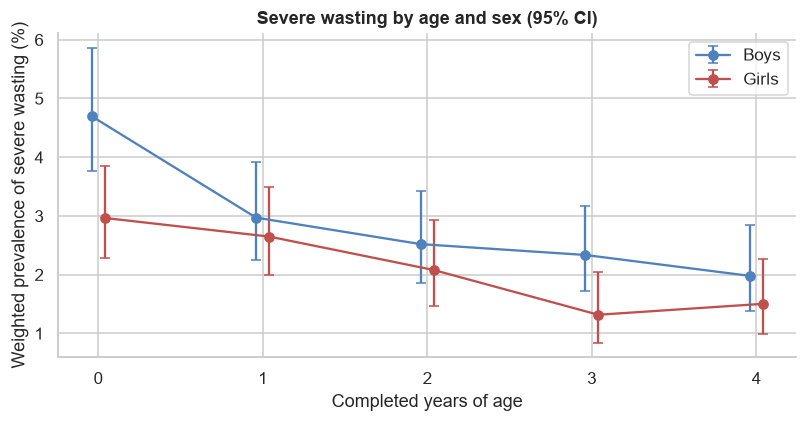

female  Boys %  Girls %
age                    
0         4.70     2.97
1         2.97     2.65
2         2.52     2.08
3         2.34     1.32
4         1.98     1.50


In [11]:
# Weighted prevalence by single year of age and sex.
d = df_clean.assign(age_sex=df_clean.ub2.astype(int).astype(str) + "|" + df_clean.female.astype(int).astype(str))
e = prev_by(d, "age_sex").reset_index().rename(columns={"index": "age_sex"})
e[["age", "female"]] = e["age_sex"].str.split("|", expand=True).astype(int)
fig, ax = plt.subplots(figsize=(7.5, 4))
for f_, c, name in [(0, "#4f81bd", "Boys"), (1, "#c0504d", "Girls")]:
    s = e[e.female == f_]
    ax.errorbar(s.age + (0.04 if f_ else -0.04), s.est, yerr=[s.est - s.lci, s.uci - s.est], marker="o", capsize=3, color=c, label=name)
ax.set_xticks(range(5)); ax.set_xlabel("Completed years of age"); ax.set_ylabel("Weighted prevalence of severe wasting (%)")
ax.set_title("Severe wasting by age and sex (95% CI)"); ax.legend(); plt.tight_layout(); plt.show()
print(e.pivot(index="age", columns="female", values="est").round(2).rename(columns={0: "Boys %", 1: "Girls %"}))

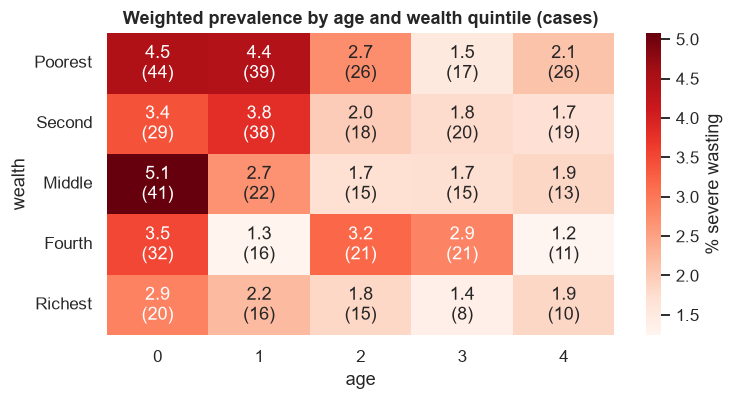

In [12]:
# Age x wealth: where is prevalence highest? (cells with few cases are noisy; counts shown in parentheses)
e = prev_by(df_clean.assign(aw=df_clean.ub2.astype(int).astype(str) + "|" + df_clean.wealth.astype(int).astype(str)), "aw").reset_index()
e[["age", "wealth"]] = e["index"].str.split("|", expand=True).astype(int)
hm = e.pivot(index="wealth", columns="age", values="est"); cs = e.pivot(index="wealth", columns="age", values="cases")
fig, ax = plt.subplots(figsize=(7, 3.8))
sns.heatmap(hm, annot=hm.round(1).astype(str) + "\n(" + cs.astype(int).astype(str) + ")", fmt="", cmap="Reds", cbar_kws={"label": "% severe wasting"}, ax=ax)
ax.set_yticklabels([lab("wealth", i) for i in hm.index], rotation=0); ax.set_title("Weighted prevalence by age and wealth quintile (cases)")
plt.tight_layout(); plt.show()

## 6. Geography

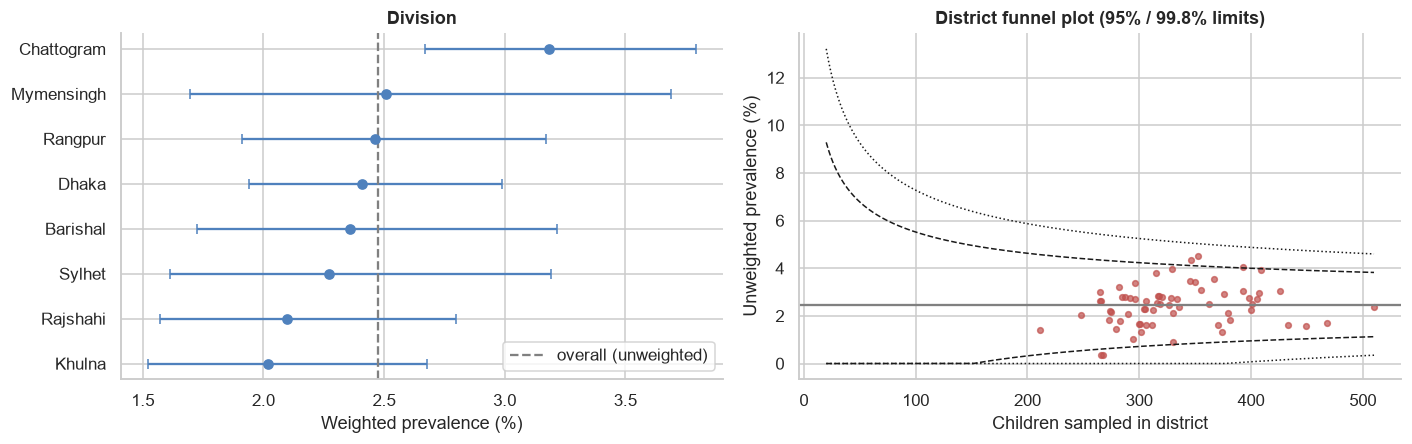

Districts outside the 95% limits: 5 of 67 (about 3 expected by chance alone)
Highest-prevalence districts with n >= 100:
                             size  sum   pct
hh7a                                        
THAKURGAON                    353   16  4.53
CHATTOGRAM CITY CORPORATION   346   15  4.34
CHATTOGRAM                    393   16  4.07
FARIDPUR                      329   13  3.95
CUMILLA                       409   16  3.91


In [13]:
# Division prevalence with design-based CIs, and district funnel plot (is between-district spread more than chance?).
e = prev_by(df_clean, "division").reset_index().rename(columns={"index": "division"})
e["name"] = e.division.map(lambda v: lab("division", v)); e = e.sort_values("est")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].errorbar(e.est, range(len(e)), xerr=[e.est - e.lci, e.uci - e.est], fmt="o", capsize=3, color="#4f81bd")
ax[0].axvline(df_clean.severe_wasting.mean() * 100, color="gray", ls="--", label="overall (unweighted)")
ax[0].set_yticks(range(len(e))); ax[0].set_yticklabels(e.name); ax[0].set_xlabel("Weighted prevalence (%)"); ax[0].set_title("Division"); ax[0].legend()
dd = df_clean.groupby("hh7a").severe_wasting.agg(["mean", "size", "sum"])
p0 = df_clean.severe_wasting.mean(); nn = np.arange(20, dd["size"].max() + 1)
ax[1].scatter(dd["size"], dd["mean"] * 100, s=14, alpha=.7, color="#c0504d")
for z_, ls in [(1.96, "--"), (3.09, ":")]:
    ax[1].plot(nn, (p0 + z_ * np.sqrt(p0 * (1 - p0) / nn)) * 100, "k" + ls, lw=1); ax[1].plot(nn, np.clip(p0 - z_ * np.sqrt(p0 * (1 - p0) / nn), 0, None) * 100, "k" + ls, lw=1)
ax[1].axhline(p0 * 100, color="gray"); ax[1].set_xlabel("Children sampled in district"); ax[1].set_ylabel("Unweighted prevalence (%)")
ax[1].set_title("District funnel plot (95% / 99.8% limits)"); plt.tight_layout(); plt.show()
out = ((dd["mean"] > p0 + 1.96 * np.sqrt(p0 * (1 - p0) / dd["size"])) | (dd["mean"] < p0 - 1.96 * np.sqrt(p0 * (1 - p0) / dd["size"]))).sum()
print(f"Districts outside the 95% limits: {out} of {len(dd)} (about {0.05*len(dd):.0f} expected by chance alone)")
print("Highest-prevalence districts with n >= 100:"); print(dd[dd["size"] >= 100].sort_values("mean", ascending=False).head(5).assign(pct=lambda x: (x["mean"]*100).round(2))[["size", "sum", "pct"]])

## 7. Household and maternal profile

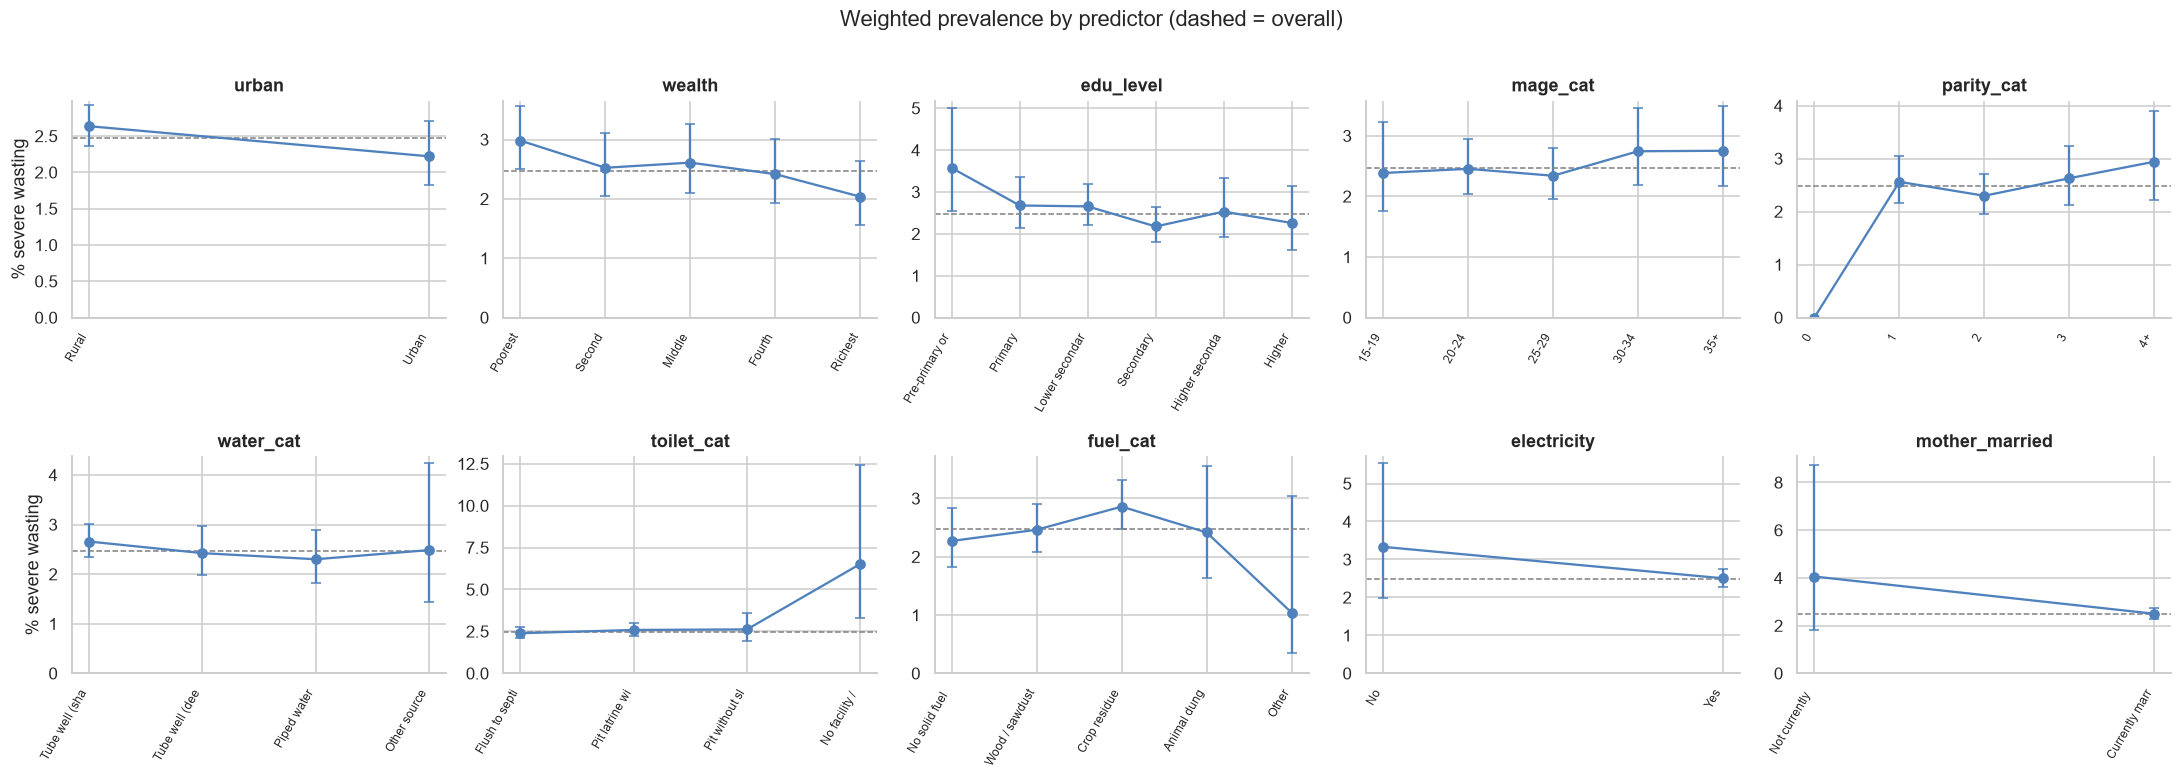

Categories with fewer than 15 cases (variable, level, n, cases):
   ('parity_cat', '0', 29, 0)
   ('toilet_cat', 'No facility / other', 247, 12)
   ('fuel_cat', 'Other', 347, 5)
   ('mother_married', 'Not currently married', 232, 9)


[None, None, None, None]

In [14]:
# Weighted prevalence for every categorical / ordinal predictor in one view (95% CI).
vars_ = ["urban", "wealth", "edu_level", "mage_cat", "parity_cat", "water_cat", "toilet_cat", "fuel_cat", "electricity", "mother_married"]
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, v in zip(axes.ravel(), vars_):
    e = prev_by(df_clean, v).reset_index().rename(columns={"index": v})
    ax.errorbar(range(len(e)), e.est, yerr=[e.est - e.lci, e.uci - e.est], fmt="o-", capsize=3, color="#4f81bd")
    ax.set_xticks(range(len(e))); ax.set_xticklabels([lab(v, x)[:14] for x in e[v]], rotation=60, ha="right", fontsize=8)
    ax.axhline(df_clean.severe_wasting.mean() * 100, color="gray", ls="--", lw=1); ax.set_title(v); ax.set_ylim(0, None)
axes[0, 0].set_ylabel("% severe wasting"); axes[1, 0].set_ylabel("% severe wasting")
plt.suptitle("Weighted prevalence by predictor (dashed = overall)", y=1.01); plt.tight_layout(); plt.show()
# Small categories whose estimates will be unstable in any model:
small = [(v, lab(v, k), int(c), int(cs)) for v in vars_ for k, c, cs in zip(*[prev_by(df_clean, v).index, prev_by(df_clean, v).n, prev_by(df_clean, v).cases]) if cs < 15]
print("Categories with fewer than 15 cases (variable, level, n, cases):"); [print("  ", s) for s in small]

## 8. Recent illness and age (confounding check)

In [15]:
# Illness is far more common in young children, and so is wasting: age can confound the illness association.
rows = []
for v in ["diarrhoea_2w", "cough_2w", "breathing_2w"]:
    for a, g in df_clean.groupby("ub2"):
        s = g[[v, "chweight"]].dropna(); rows.append((v, int(a), np.average(s[v], weights=s.chweight) * 100))
il = pd.DataFrame(rows, columns=["illness", "age", "pct"]).pivot(index="age", columns="illness", values="pct").round(1)
print("Weighted % with illness in last 2 weeks, by age:"); print(il)
# Diarrhoea and severe wasting, within age bands (stratified, design-based).
d = df_clean.assign(band=np.where(df_clean.young == 1, "Age 0-1", "Age 2-4"))
d["grp"] = d.band + " | diarrhoea=" + d.diarrhoea_2w.map({0.0: "no", 1.0: "yes"})
e = prev_by(d, "grp"); print("\nSevere wasting % by diarrhoea within age band:"); print(e[["est", "lci", "uci", "n", "cases"]].round(2))

Weighted % with illness in last 2 weeks, by age:
illness  breathing_2w  cough_2w  diarrhoea_2w
age                                          
0                13.4      32.2           9.7
1                13.4      33.2          10.4
2                 9.0      28.6           6.7
3                 8.1      25.1           4.6
4                 7.3      23.1           3.9

Severe wasting % by diarrhoea within age band:
                          est   lci   uci      n  cases
Age 0-1 | diarrhoea=no   3.20  2.79  3.66   8011    262
Age 0-1 | diarrhoea=yes  4.38  2.95  6.46    874     35
Age 2-4 | diarrhoea=no   1.93  1.66  2.24  12716    234
Age 2-4 | diarrhoea=yes  2.84  1.71  4.69    700     20


## 9. Overlap between predictors

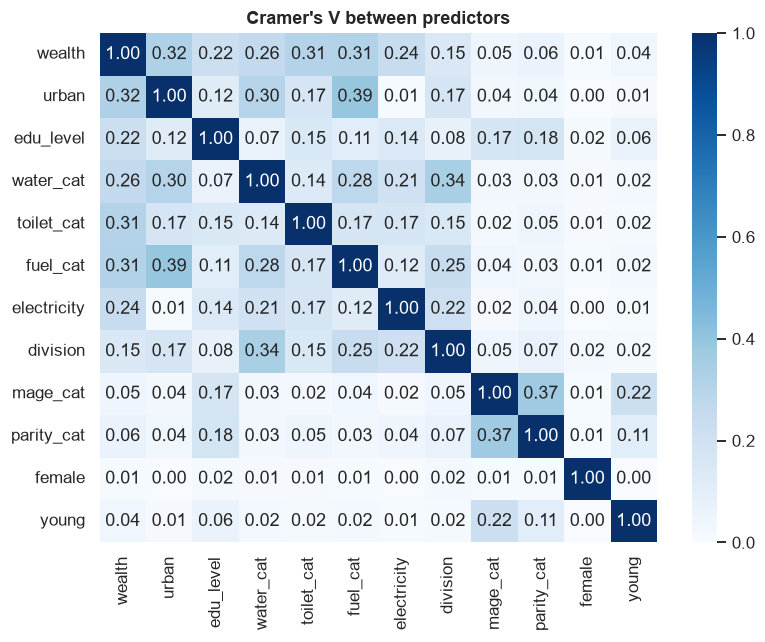

Most overlapping pairs:
urban      fuel_cat      0.39
mage_cat   parity_cat    0.37
water_cat  division      0.34
wealth     urban         0.32
           fuel_cat      0.31
           toilet_cat    0.31

VIF: {'ub2': np.float64(1.06), 'female': np.float64(1.0), 'wealth': np.float64(1.92), 'urban': np.float64(1.18), 'edu_level': np.float64(1.37), 'mage_cat': np.float64(1.87), 'parity_cat': np.float64(1.95), 'water_cat': np.float64(1.22), 'toilet_cat': np.float64(1.24), 'fuel_cat': np.float64(1.44)}


In [16]:
# Cramer's V between categorical predictors (unweighted, exploratory) to see which variables carry the same information.
from scipy.stats import chi2_contingency
cv = ["wealth", "urban", "edu_level", "water_cat", "toilet_cat", "fuel_cat", "electricity", "division", "mage_cat", "parity_cat", "female", "young"]
def cramers_v(a, b):
    t = pd.crosstab(a, b); chi2 = chi2_contingency(t, correction=False)[0]; n = t.values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1)))
V = pd.DataFrame([[cramers_v(df_clean[a], df_clean[b]) if a != b else 1 for b in cv] for a in cv], index=cv, columns=cv)
fig, ax = plt.subplots(figsize=(7.5, 6)); sns.heatmap(V, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Cramer's V between predictors"); plt.tight_layout(); plt.show()
pairs = V.where(np.triu(np.ones(V.shape, bool), 1)).stack().sort_values(ascending=False).head(6)
print("Most overlapping pairs:"); print(pairs.round(2).to_string())
# Variance inflation for the numeric/ordinal coding of the core predictors.
from statsmodels.stats.outliers_influence import variance_inflation_factor as _vif
Xv = df_clean[["ub2", "female", "wealth", "urban", "edu_level", "mage_cat", "parity_cat", "water_cat", "toilet_cat", "fuel_cat"]].dropna()
Xv = sm.add_constant(Xv)
print("\nVIF:", {c: round(_vif(Xv.values, i), 2) for i, c in enumerate(Xv.columns) if c != "const"})

## 10. Infants aged 0-1: feeding and antenatal care

dds equals the sum of the seven food-group indicators in 100.0% of 8,815 children with complete data
=> dds and fg_* carry the same information and must not enter one model together.

Weighted % who ate each food group yesterday:
           age 0 (%)  age 1 (%)
group                          
fg_dairy        25.5       33.0
fg_egg          16.9       44.3
fg_flesh        13.1       53.5
fg_grain        39.6       89.6
fg_legume        6.1       20.8
fg_ofv          15.6       41.1
fg_vita         16.2       45.9


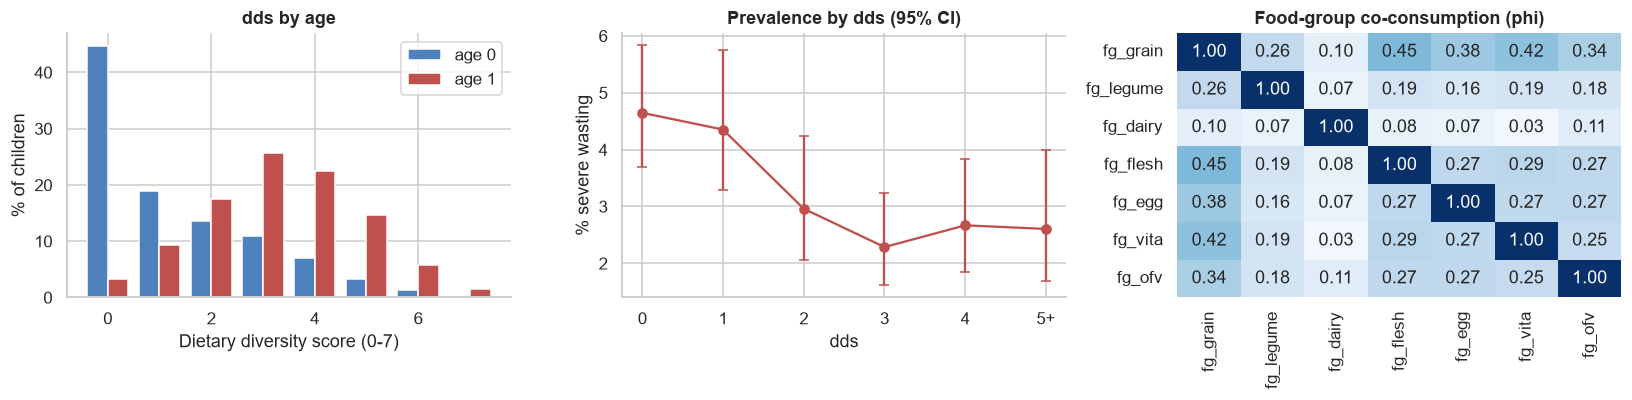

In [17]:
# NOTE: "age 0-1" means completed years 0 and 1, i.e. children under 2.
yi = df_clean[df_clean.young == 1].copy()
fg = ["fg_grain", "fg_legume", "fg_dairy", "fg_flesh", "fg_egg", "fg_vita", "fg_ofv"]
_ok = yi[fg + ["dds"]].notna().all(axis=1)
print("dds equals the sum of the seven food-group indicators in", f"{(yi.loc[_ok, 'dds'] == yi.loc[_ok, fg].sum(axis=1)).mean()*100:.1f}% of {int(_ok.sum()):,} children with complete data")
print("=> dds and fg_* carry the same information and must not enter one model together.\n")
rows = []
for v in fg:
    for a in (0, 1):
        s = yi[yi.ub2 == a][[v, "chweight"]].dropna(); rows.append((v, a, np.average(s[v], weights=s.chweight) * 100))
fgt = pd.DataFrame(rows, columns=["group", "age", "pct"]).pivot(index="group", columns="age", values="pct").round(1)
fgt.columns = ["age 0 (%)", "age 1 (%)"]; print("Weighted % who ate each food group yesterday:"); print(fgt)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c in [(0, "#4f81bd"), (1, "#c0504d")]:
    s = yi[(yi.ub2 == a) & yi.dds.notna()]; h = s.groupby("dds").chweight.sum() / s.chweight.sum() * 100
    ax[0].bar(h.index + (0.2 if a else -0.2), h.values, width=0.4, color=c, label=f"age {a}")
ax[0].set_xlabel("Dietary diversity score (0-7)"); ax[0].set_ylabel("% of children"); ax[0].set_title("dds by age"); ax[0].legend()
e = prev_by(yi.assign(dds_c=yi.dds.clip(upper=5)), "dds_c").reset_index().rename(columns={"index": "dds"})
ax[1].errorbar(e.dds, e.est, yerr=[e.est - e.lci, e.uci - e.est], fmt="o-", capsize=3, color="#c0504d")
ax[1].set_xticks(range(6)); ax[1].set_xticklabels(["0", "1", "2", "3", "4", "5+"]); ax[1].set_xlabel("dds"); ax[1].set_ylabel("% severe wasting"); ax[1].set_title("Prevalence by dds (95% CI)")
corr = yi[fg].corr(); sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax[2], cbar=False); ax[2].set_title("Food-group co-consumption (phi)")
plt.tight_layout(); plt.show()

In [18]:
# Breastfeeding, bottle feeding and ANC: how common, how they vary with age and wealth, and prevalence by group.
for v in ["bf_status", "anc_cat", "bottle"]:
    e = prev_by(yi, v).reset_index().rename(columns={"index": v}); e[v] = e[v].map(lambda x: lab(v, x))
    print(f"\n{v}: weighted prevalence of severe wasting"); print(e[[v, "est", "lci", "uci", "n", "cases"]].round(2).to_string(index=False))
_anc = pd.crosstab(yi.wealth, yi.anc_cat, normalize="index") * 100
_anc.index = [lab("wealth", i) for i in _anc.index]; _anc.columns = [lab("anc_cat", c) for c in _anc.columns]
print("\nANC category by wealth (row %, unweighted, wealth missing ANC excluded):"); print(_anc.round(1))
_dd = yi.groupby("wealth").dds.mean().round(2); _dd.index = [lab("wealth", i) for i in _dd.index]
print("\nMean dds by wealth:"); print(_dd.to_string())


bf_status: weighted prevalence of severe wasting
          bf_status  est  lci  uci    n  cases
    Never breastfed 2.66 1.24 5.61  188      7
Ever, not yesterday 2.10 1.16 3.76  546     15
Breastfed yesterday 3.41 2.99 3.89 8151    275

anc_cat: weighted prevalence of severe wasting
   anc_cat  est  lci  uci    n  cases
    No ANC 4.88 3.27 7.24  689     33
1-3 visits 3.68 3.10 4.37 4406    162
 4+ visits 2.58 2.05 3.25 3703     97

bottle: weighted prevalence of severe wasting
bottle  est  lci  uci    n  cases
   0.0 3.33 2.87 3.85 6854    231
   1.0 3.27 2.50 4.27 2032     66

ANC category by wealth (row %, unweighted, wealth missing ANC excluded):
         No ANC  1-3 visits  4+ visits
Poorest    17.8        59.6       22.6
Second      8.2        57.9       33.9
Middle      6.2        52.5       41.3
Fourth      3.6        45.6       50.8
Richest     1.6        30.8       67.6

Mean dds by wealth:
Poorest    2.02
Second     2.21
Middle     2.33
Fourth     2.50
Richest    2.80


## 11. Data-validity checks

In [19]:
checks = {
 "child_id unique": df_clean.child_id.is_unique,
 "ub2 within 0-4": df_clean.ub2.between(0, 4).all(),
 "young == (ub2 <= 1)": ((df_clean.ub2 <= 1).astype(int) == df_clean.young).all(),
 "dds within 0-7": df_clean.dds.dropna().between(0, 7).all(),
 "infant-only vars empty at ages 2-4": df_clean.loc[df_clean.young == 0, ["dds", "bf_status", "bottle", "anc_cat"]].isna().all().all(),
 "chweight > 0": (df_clean.chweight > 0).all(),
 "mother age 15-49": df_clean.wb4.dropna().between(15, 49).all(),
 "parity_cat consistent with cm11 (cm11 >= 4 -> '4+')": ((df_clean.cm11 >= 4) == (df_clean.parity_cat == 4)).all(),
}
for k, v in checks.items(): print(("PASS  " if v else "FAIL  ") + k)
mm = df_clean.groupby("mother_id").size()
print(f"\nMothers with more than one child in the file: {(mm>1).sum():,} ({mm[mm>1].sum():,} children): siblings share household factors, which cluster-level SEs on hh1 already absorb.")
odd = df_clean[df_clean.cm11 == 0]
print(f"Children whose caretaker reports 0 live births (cm11 = 0): {len(odd)}  (cases: {int(odd.severe_wasting.sum())}) -> the caretaker is probably not the biological mother; these form the sparse parity_cat == 0 group.")

PASS  child_id unique
PASS  ub2 within 0-4
PASS  young == (ub2 <= 1)
PASS  dds within 0-7
PASS  infant-only vars empty at ages 2-4
PASS  chweight > 0
PASS  mother age 15-49
PASS  parity_cat consistent with cm11 (cm11 >= 4 -> '4+')

Mothers with more than one child in the file: 2,294 (4,635 children): siblings share household factors, which cluster-level SEs on hh1 already absorb.
Children whose caretaker reports 0 live births (cm11 = 0): 29  (cases: 0) -> the caretaker is probably not the biological mother; these form the sparse parity_cat == 0 group.


## 12. What the exploration shows

**Data and definition**
- `severe_wasting` is exactly WHZ < -3 (552 children, all with WHZ between -4.96 and -3.01); the moderate (-3 to -2) group is a separate category, so the outcome and the dropped predictors are cleanly separated.
- Weighted prevalence is 2.52% (95% CI 2.29-2.77); unweighted 2.47%.
- Infant-only variables (`dds`, `fvs`, `fg_*`, `bf_status`, `bottle`, `anc_cat`) are 60% missing overall but only 0-1% missing in children aged 0-1, so the missingness is structural, not a data-quality problem. `bd9` (meal frequency) is missing for 27% of children even within ages 0-1 and is best left out. Only 294 children (1.3%) lack a core-model predictor.

**Survey design**
- The design effect (about 1.34) comes almost entirely from the weights (1.36 from weighting alone), not from clustering: the PSU dispersion ratio is 1.04 and the ICC is about 0.0003. Weights must be used; cluster correction matters little for this outcome.
- No stratum has a single PSU (33-451 PSUs each), so the lonely-PSU setting (`adjust` in R vs `centered` in Stata) does not matter here.

**Patterns**
- Prevalence falls steadily with age (highest in the first year of life) and is higher in boys; the sex gap is largest at age 0 (4.70% vs 2.97%).
- Geography: 5 of 67 districts fall outside the 95% funnel limits (about 3 expected), so district-level variation is mild; the division-level pattern is modest.
- Recent illness is most common at ages 0-1 where wasting is also most common. Within each age band, children with diarrhoea still have higher prevalence (about 1.4 times higher in both bands), so age explains part, not all, of the crude association.
- Several categories have too few cases for stable estimates: `toilet_cat` 3 (12 cases), `fuel_cat` 4 (5), unmarried mothers (9), and `parity_cat` 0 (29 children, 0 cases; these caretakers report zero live births, so they are probably not the biological mother).
- Predictors overlap only moderately (largest Cramer's V about 0.39; VIF below 2 for the main predictors).

**Infants aged 0-1 (children under 2)**
- `dds` is the sum of the seven `fg_*` indicators, so they cannot be modelled together. Use `dds` or the individual food groups, not both.
- Feeding is strongly age-dependent: grains rise from about 40% at age 0 to about 90% at age 1, flesh foods from 13% to 54%. Because prevalence also falls with age, these associations are partly age effects and need age adjustment.
- ANC and wealth are tightly linked: 17.8% of the poorest infants had no ANC vs 1.6% of the richest, and dietary diversity also rises with wealth. The univariate ANC and diet signals are therefore partly wealth and age, which is why they weaken after adjustment (see `analysis_followup.R`).

# Statistical Tests

## Univariate Tests

### Frequencies

In [20]:
# Compute unweighted frequencies and survey-weighted percentages across the full cleaned sample (df_clean).
cat_ord_bin_vars = [
    'female', 'urban', 'division', 'water_cat', 'toilet_cat', 'fuel_cat',
    'diarrhoea_2w', 'cough_2w', 'breathing_2w', 'any_illness', 'electricity',
    'insured', 'mother_married', 'edu_level', 'wealth', 'mage_cat', 'parity_cat'
]

univariate_cat = []
for col in cat_ord_bin_vars:
    sub = df_clean[[col, 'chweight']].dropna()
    total_w = sub['chweight'].sum()
    grp = sub.groupby(col).agg(unweighted_n=('chweight', 'count'), weighted_n=('chweight', 'sum'))
    grp['weighted_pct'] = (grp['weighted_n'] / total_w) * 100
    grp['variable'] = col
    grp['category'] = grp.index
    univariate_cat.append(grp.reset_index(drop=True))

df_uni_cat = pd.concat(univariate_cat, ignore_index=True)[['variable', 'category', 'unweighted_n', 'weighted_n', 'weighted_pct']]
print(df_uni_cat.to_string(index=False))

      variable  category  unweighted_n   weighted_n  weighted_pct
        female       0.0         11514 11530.763152     51.831736
        female       1.0         10797 10715.767531     48.168264
         urban       0.0         16392 15854.161689     71.265771
         urban       1.0          5919  6392.368994     28.734229
      division       1.0          1894  1192.500326      5.360388
      division       2.0          4904  5197.752491     23.364328
      division       3.0          4689  5411.883895     24.326867
      division       4.0          2987  2294.547704     10.314182
      division       5.0          1331  1769.402892      7.953613
      division       6.0          2260  2581.909888     11.605899
      division       7.0          2705  2402.019776     10.797278
      division       8.0          1541  1396.513712      6.277445
     water_cat       0.0         11746 11496.470822     51.677590
     water_cat       1.0          5501  4729.404849     21.259067
     water

In [21]:
# Calculate survey-weighted mean, SD, median, and IQR for continuous predictors on df_clean.
cont_vars = ['ub2', 'dds', 'fvs', 'wb4', 'cm11', 'bd9']
univariate_cont = []

for col in cont_vars:
    valid = df_clean[[col, 'chweight']].dropna()
    wq = DescrStatsW(valid[col], weights=valid['chweight'], ddof=0)
    q25, q50, q75 = wq.quantile([0.25, 0.50, 0.75])
    univariate_cont.append({
        'variable': col,
        'unweighted_n': len(valid),
        'weighted_mean': round(wq.mean, 4),
        'weighted_sd': round(wq.std, 4),
        'weighted_median': q50,
        'weighted_iqr': q75 - q25
    })

print(pd.DataFrame(univariate_cont).to_string(index=False))

variable  unweighted_n  weighted_mean  weighted_sd  weighted_median  weighted_iqr
     ub2         22311         1.9844       1.3926              2.0           2.0
     dds          8815         2.3525       1.8323              2.0           3.0
     fvs          8799         2.9130       2.4297              3.0           4.0
     wb4         22052        27.3234       6.2834             26.0           9.0
    cm11         22043         2.1615       1.1086              2.0           2.0
     bd9          6528         4.1181       1.8963              4.0           3.0


### Rao-Scott F-tests

In [22]:
# Compute unweighted counts, Stata-centered 95% CIs, and Rao-Scott F-tests for binary and nominal variables.
bin_nom_vars = [
    'female', 'urban', 'electricity', 'insured', 'mother_married',
    'diarrhoea_2w', 'cough_2w', 'breathing_2w', 'any_illness',
    'division', 'water_cat', 'toilet_cat', 'fuel_cat'
]

bin_nom_summary = []

for col in bin_nom_vars:
    sub = df_clean[['severe_wasting', 'chweight', 'strata', 'hh1', col]].dropna().copy()
    unw_tab = pd.crosstab(sub[col], sub['severe_wasting'])
    est_df, _ = svy_prop_stata_centered(sub, 'severe_wasting', 'chweight', 'strata', 'hh1', col)
    
    comb_tab = pd.DataFrame({
        'Unw_No_Wasting': unw_tab[0],
        'Unw_Severe_Wasting': unw_tab[1],
        'Weighted_Prev_%': est_df['est'].round(2),
        'CI_95_Low_%': est_df['lci'].round(2),
        'CI_95_High_%': est_df['uci'].round(2)
    })
    print(f"\n--- Contingency Table & Design 95% CI: {col} ---")
    print(comb_tab)
    
    chi2_p, f_stat, dof, p_val = rao_scott_chisquare(sub, 'severe_wasting', 'chweight', 'strata', 'hh1', col)
    bin_nom_summary.append({
        'variable': col,
        'pearson_chi2': chi2_p,
        'rao_scott_F': f_stat,
        'df': dof,
        'p_value': p_val
    })

print("\n--- Second-Order Rao-Scott Summary (Binary & Nominal) ---")
print(pd.DataFrame(bin_nom_summary).to_string(index=False))


--- Contingency Table & Design 95% CI: female ---
   Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
0           11199                 315             2.89         2.55   
1           10560                 237             2.11         1.82   

   CI_95_High_%  
0          3.27  
1          2.46  

--- Contingency Table & Design 95% CI: urban ---
   Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
0           15970                 422             2.64         2.37   
1            5789                 130             2.22         1.82   

   CI_95_High_%  
0          2.93  
1          2.71  

--- Contingency Table & Design 95% CI: electricity ---
   Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
0             665                  22             3.33         1.99   
1           21094                 530             2.50         2.27   

   CI_95_High_%  
0          5.54  
1          2.76  

--- Contingency Table & Design 95% CI:

In [23]:
# Generate contingency tables with 95% CIs, Rao-Scott F-tests, and design-adjusted linear trend tests for ordered variables.
ord_vars = ['wealth', 'edu_level', 'ub2', 'parity_cat', 'mage_cat']
ord_trend_summary = []

for col in ord_vars:
    sub = df_clean[['severe_wasting', 'chweight', 'strata', 'hh1', col]].dropna().copy()
    unw_tab = pd.crosstab(sub[col], sub['severe_wasting'])
    est_df, _ = svy_prop_stata_centered(sub, 'severe_wasting', 'chweight', 'strata', 'hh1', col)
    
    comb_tab = pd.DataFrame({
        'Unw_No_Wasting': unw_tab[0],
        'Unw_Severe_Wasting': unw_tab[1],
        'Weighted_Prev_%': est_df['est'].round(2),
        'CI_95_Low_%': est_df['lci'].round(2),
        'CI_95_High_%': est_df['uci'].round(2)
    })
    print(f"\n--- Ordered Contingency Table & 95% CI: {col} ---")
    print(comb_tab)
    
    chi2_p, f_stat, dof, rs_pval = rao_scott_chisquare(sub, 'severe_wasting', 'chweight', 'strata', 'hh1', col)
    m_trend = smf.glm(f"severe_wasting ~ {col}", data=sub, family=sm.families.Binomial(), var_weights=sub['chweight']).fit(cov_type='cluster', cov_kwds={'groups': sub['hh1']})
    or_val = np.exp(m_trend.params[col])
    ci_low, ci_high = np.exp(m_trend.conf_int().loc[col])
    
    ord_trend_summary.append({
        'ordered_variable': col,
        'rao_scott_F': f_stat,
        'rao_scott_p': rs_pval,
        'trend_OR_step': round(or_val, 4),
        'CI_95_Low': round(ci_low, 4),
        'CI_95_High': round(ci_high, 4),
        'trend_z': round(m_trend.tvalues[col], 4),
        'trend_p_value': round(m_trend.pvalues[col], 4)
    })

print("\n--- Design-Adjusted Trend & Rao-Scott Summary (Ordered) ---")
print(pd.DataFrame(ord_trend_summary).to_string(index=False))


--- Ordered Contingency Table & 95% CI: wealth ---
   Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
1            5069                 152             2.98         2.50   
2            4652                 124             2.52         2.04   
3            4349                 106             2.61         2.09   
4            4115                 101             2.42         1.93   
5            3574                  69             2.04         1.57   

   CI_95_High_%  
1          3.56  
2          3.11  
3          3.25  
4          3.02  
5          2.64  


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(



--- Ordered Contingency Table & 95% CI: edu_level ---
     Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
0.0            1193                  43             3.57         2.53   
1.0            3867                  99             2.68         2.13   
2.0            5561                 149             2.65         2.21   
3.0            6025                 139             2.18         1.80   
4.0            2733                  67             2.53         1.92   
5.0            2125                  47             2.26         1.61   

     CI_95_High_%  
0.0          5.01  
1.0          3.36  
2.0          3.19  
3.0          2.63  
4.0          3.32  
5.0          3.15  


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(



--- Ordered Contingency Table & 95% CI: ub2 ---
     Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
0.0            4073                 166             3.86         3.26   
1.0            4518                 131             2.82         2.32   
2.0            4545                  95             2.30         1.83   
3.0            4389                  81             1.85         1.43   
4.0            4234                  79             1.75         1.34   

     CI_95_High_%  
0.0          4.56  
1.0          3.42  
2.0          2.90  
3.0          2.39  
4.0          2.30  


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(



--- Ordered Contingency Table & 95% CI: parity_cat ---
     Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
0.0              29                   0             0.00         0.00   
1.0            6572                 170             2.56         2.16   
2.0            8084                 194             2.30         1.95   
3.0            4473                 115             2.63         2.13   
4.0            2341                  65             2.94         2.21   

     CI_95_High_%  
0.0          0.00  
1.0          3.04  
2.0          2.70  
3.0          3.24  
4.0          3.90  


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(



--- Ordered Contingency Table & 95% CI: mage_cat ---
     Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
1.0            1755                  50             2.39         1.76   
2.0            6378                 153             2.45         2.05   
3.0            6121                 159             2.34         1.96   
4.0            3992                  98             2.74         2.18   
5.0            3262                  84             2.75         2.16   

     CI_95_High_%  
1.0          3.23  
2.0          2.94  
3.0          2.79  
4.0          3.45  
5.0          3.49  

--- Design-Adjusted Trend & Rao-Scott Summary (Ordered) ---
ordered_variable  rao_scott_F  rao_scott_p  trend_OR_step  CI_95_Low  CI_95_High  trend_z  trend_p_value
          wealth       1.4856       0.2035         0.9219     0.8591      0.9892  -2.2617         0.0237
       edu_level       1.4017       0.2201         0.9308     0.8609      1.0063  -1.8026         0.0714
           

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


### Univariate logistic regression

In [24]:
# Fit univariable survey-weighted logistic regression and check linearity using quartiles and cubic splines for wb4 and cm11.
cont_vars = ['wb4', 'cm11']
cont_summary = []

for col in cont_vars:
    sub = df_clean[['severe_wasting', 'chweight', 'strata', 'hh1', col]].dropna().copy()
    m_lin = smf.glm(f"severe_wasting ~ {col}", data=sub, family=sm.families.Binomial(), var_weights=sub['chweight']).fit(cov_type='cluster', cov_kwds={'groups': sub['hh1']})
    
    sub['quartile'] = pd.qcut(sub[col], q=4, duplicates='drop')
    unw_q = pd.crosstab(sub['quartile'], sub['severe_wasting'])
    w_q = pd.crosstab(sub['quartile'], sub['severe_wasting'], values=sub['chweight'], aggfunc='sum')
    q_tab = pd.DataFrame({
        'Unw_No_Wasting': unw_q[0],
        'Unw_Severe_Wasting': unw_q[1],
        'Weighted_Prev_%': ((w_q[1] / w_q.sum(axis=1)) * 100).round(2)
    })
    print(f"\n--- Quartile Linearity Check Table: {col} ---")
    print(q_tab)
    
    m_spline = smf.glm(f"severe_wasting ~ bs({col}, df=3)", data=sub, family=sm.families.Binomial(), var_weights=sub['chweight']).fit(cov_type='cluster', cov_kwds={'groups': sub['hh1']})
    R_spline = np.eye(len(m_spline.params))[1:]
    spline_wald = m_spline.wald_test(R_spline, scalar=True)
    
    cont_summary.append({
        'variable': col,
        'linear_OR': round(np.exp(m_lin.params[col]), 4),
        'linear_wald_z': round(m_lin.tvalues[col], 4),
        'linear_p_value': round(m_lin.pvalues[col], 4),
        'spline_chi2_stat': round(float(spline_wald.statistic), 4),
        'spline_p_value': round(float(spline_wald.pvalue), 4)
    })

print("\n--- Continuous & Count Linearity Summary ---")
print(pd.DataFrame(cont_summary).to_string(index=False))

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(



--- Quartile Linearity Check Table: wb4 ---
                Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%
quartile                                                           
(14.999, 22.0]            5484                 153             2.69
(22.0, 26.0]              5380                 116             1.98
(26.0, 31.0]              5307                 146             2.80
(31.0, 49.0]              5337                 129             2.58


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(
C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(



--- Quartile Linearity Check Table: cm11 ---
               Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%
quartile                                                          
(-0.001, 1.0]            6601                 170             2.55
(1.0, 2.0]               8084                 194             2.30
(2.0, 3.0]               4473                 115             2.63
(3.0, 9.0]               2341                  65             2.94

--- Continuous & Count Linearity Summary ---
variable  linear_OR  linear_wald_z  linear_p_value  spline_chi2_stat  spline_p_value
     wb4     1.0028         0.3573          0.7209            2.9620          0.3975
    cm11     1.0652         1.3042          0.1922            4.6273          0.2012


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


### Rao-Scott $\chi^2$

In [25]:
# Filter subpopulation to children aged 0-1 (young == 1) and run Rao-Scott chi-square and Stata-centered 95% CIs on infant variables.
df_young = df_clean[df_clean['young'] == 1].copy()

young_cat_vars = [
    'fg_grain', 'fg_legume', 'fg_dairy', 'fg_flesh', 'fg_egg',
    'fg_vita', 'fg_ofv', 'bf_status', 'bottle', 'anc_cat'
]
young_cat_summary = []

for col in young_cat_vars:
    sub = df_young[['severe_wasting', 'chweight', 'strata', 'hh1', col]].dropna().copy()
    unw_tab = pd.crosstab(sub[col], sub['severe_wasting'])
    est_df, _ = svy_prop_stata_centered(sub, 'severe_wasting', 'chweight', 'strata', 'hh1', col)
    
    comb_tab = pd.DataFrame({
        'Unw_No_Wasting': unw_tab[0],
        'Unw_Severe_Wasting': unw_tab[1],
        'Weighted_Prev_%': est_df['est'].round(2),
        'CI_95_Low_%': est_df['lci'].round(2),
        'CI_95_High_%': est_df['uci'].round(2)
    })
    print(f"\n--- Ages 0-1 Contingency Table & 95% CI: {col} ---")
    print(comb_tab)
    
    chi2_p, f_stat, dof, p_val = rao_scott_chisquare(sub, 'severe_wasting', 'chweight', 'strata', 'hh1', col)
    young_cat_summary.append({
        'infant_variable': col,
        'pearson_chi2': chi2_p,
        'rao_scott_F': f_stat,
        'df': dof,
        'p_value': p_val
    })

print("\n--- Ages 0-1 Rao-Scott Summary ---")
print(pd.DataFrame(young_cat_summary).to_string(index=False))


--- Ages 0-1 Contingency Table & 95% CI: fg_grain ---
     Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
0.0            2887                 136             4.43         3.68   
1.0            5698                 161             2.73         2.29   

     CI_95_High_%  
0.0          5.34  
1.0          3.26  

--- Ages 0-1 Contingency Table & 95% CI: fg_legume ---
     Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
0.0            7428                 265             3.47         3.04   
1.0            1160                  32             2.36         1.54   

     CI_95_High_%  
0.0          3.96  
1.0          3.60  

--- Ages 0-1 Contingency Table & 95% CI: fg_dairy ---
     Unw_No_Wasting  Unw_Severe_Wasting  Weighted_Prev_%  CI_95_Low_%  \
0.0            6077                 225             3.53         3.05   
1.0            2493                  71             2.76         2.14   

     CI_95_High_%  
0.0          4.09  
1.0          3

### Wald tests for dds, fvs, ordered anc

In [26]:
# Run design-adjusted trend and univariable Wald tests for dietary diversity (dds), food variety (fvs), and ordered ANC visits within young == 1.
young_score_vars = ['dds', 'fvs', 'anc_cat']
young_score_summary = []

for col in young_score_vars:
    sub = df_young[['severe_wasting', 'chweight', 'strata', 'hh1', col]].dropna().copy()
    m_score = smf.glm(f"severe_wasting ~ {col}", data=sub, family=sm.families.Binomial(), var_weights=sub['chweight']).fit(cov_type='cluster', cov_kwds={'groups': sub['hh1']})
    or_val = np.exp(m_score.params[col])
    ci_low, ci_high = np.exp(m_score.conf_int().loc[col])
    
    young_score_summary.append({
        'infant_score_var': col,
        'trend_OR': round(or_val, 4),
        'CI_95_Low': round(ci_low, 4),
        'CI_95_High': round(ci_high, 4),
        'wald_z': round(m_score.tvalues[col], 4),
        'p_value': round(m_score.pvalues[col], 4)
    })

print("\n--- Ages 0-1 Score & Trend Summary (dds, fvs, anc_cat) ---")
print(pd.DataFrame(young_score_summary).to_string(index=False))

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(
C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(



--- Ages 0-1 Score & Trend Summary (dds, fvs, anc_cat) ---
infant_score_var  trend_OR  CI_95_Low  CI_95_High  wald_z  p_value
             dds    0.8643     0.7958      0.9387 -3.4608   0.0005
             fvs    0.9083     0.8483      0.9724 -2.7645   0.0057
         anc_cat    0.7097     0.5722      0.8804 -3.1193   0.0018


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


## Multivariate

### Survey-weighted logistic regression (Age: 0-4)

In [27]:
# Fit multivariable survey-weighted logistic regression for all children aged 0-4 (excluding infant-only variables so N=22,311 is preserved).
features_all_ages = [
    'ub2', 'female', 'diarrhoea_2w', 'cough_2w', 'breathing_2w',
    'edu_level', 'mage_cat', 'parity_cat', 'water_cat',
    'toilet_cat', 'fuel_cat', 'urban', 'wealth', 'division'
]
df_multivar_all = df_clean.dropna(subset=features_all_ages).copy()
df_multivar_all['parity_cat_collapsed'] = df_multivar_all['parity_cat'].replace({0.0: 1.0})

formula_all = "severe_wasting ~ ub2 + female + diarrhoea_2w + cough_2w + breathing_2w + C(edu_level) + C(mage_cat) + C(parity_cat_collapsed) + C(water_cat) + C(toilet_cat) + C(fuel_cat) + urban + C(wealth) + C(division)"

m_multi_all = smf.glm(formula=formula_all, data=df_multivar_all, family=sm.families.Binomial(), var_weights=df_multivar_all['chweight']).fit(cov_type='cluster', cov_kwds={'groups': df_multivar_all['hh1']})

res_all = pd.DataFrame({
    'Term': m_multi_all.params.index,
    'AOR': np.exp(m_multi_all.params.values).round(4),
    'CI_95_Low': np.exp(m_multi_all.conf_int()[0].values).round(4),
    'CI_95_High': np.exp(m_multi_all.conf_int()[1].values).round(4),
    'Wald_z': m_multi_all.tvalues.values.round(4),
    'p_value': m_multi_all.pvalues.values.round(4)
})
print(f"--- Multivariable Model: All Children 0-4 (N = {len(df_multivar_all)}) ---")
print(res_all.to_string(index=False))

--- Multivariable Model: All Children 0-4 (N = 22017) ---
                          Term    AOR  CI_95_Low  CI_95_High  Wald_z  p_value
                     Intercept 0.0486     0.0218      0.1085 -7.3760   0.0000
           C(edu_level)[T.1.0] 0.8099     0.5239      1.2521 -0.9484   0.3429
           C(edu_level)[T.2.0] 0.8493     0.5577      1.2933 -0.7614   0.4464
           C(edu_level)[T.3.0] 0.6886     0.4321      1.0973 -1.5694   0.1166
           C(edu_level)[T.4.0] 0.8317     0.4972      1.3914 -0.7018   0.4828
           C(edu_level)[T.5.0] 0.7923     0.4408      1.4242 -0.7782   0.4365
            C(mage_cat)[T.2.0] 1.3148     0.8923      1.9375  1.3838   0.1664
            C(mage_cat)[T.3.0] 1.4002     0.9192      2.1331  1.5674   0.1170
            C(mage_cat)[T.4.0] 1.7521     1.0731      2.8607  2.2420   0.0250
            C(mage_cat)[T.5.0] 1.8170     1.0835      3.0473  2.2638   0.0236
C(parity_cat_collapsed)[T.2.0] 0.8276     0.6285      1.0897 -1.3482   0.1776
C(pari

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


### Survey-weighted logistic regression (Age: 0-1)

In [28]:
# Fit multivariable survey-weighted logistic regression specifically for infants aged 0-1 (young == 1) including feeding and ANC predictors.
features_young = features_all_ages + ['dds', 'anc_cat', 'bf_status', 'bottle', 'fg_grain', 'fg_flesh']
df_multivar_young = df_young.dropna(subset=features_young).copy()
df_multivar_young['parity_cat_collapsed'] = df_multivar_young['parity_cat'].replace({0.0: 1.0})

formula_young = "severe_wasting ~ ub2 + female + diarrhoea_2w + cough_2w + breathing_2w + dds + fg_grain + fg_flesh + C(anc_cat) + C(bf_status) + bottle + C(edu_level) + C(mage_cat) + C(parity_cat_collapsed) + C(water_cat) + C(toilet_cat) + C(fuel_cat) + urban + C(wealth) + C(division)"

m_multi_young = smf.glm(formula=formula_young, data=df_multivar_young, family=sm.families.Binomial(), var_weights=df_multivar_young['chweight']).fit(cov_type='cluster', cov_kwds={'groups': df_multivar_young['hh1']})

res_young = pd.DataFrame({
    'Term': m_multi_young.params.index,
    'AOR': np.exp(m_multi_young.params.values).round(4),
    'CI_95_Low': np.exp(m_multi_young.conf_int()[0].values).round(4),
    'CI_95_High': np.exp(m_multi_young.conf_int()[1].values).round(4),
    'Wald_z': m_multi_young.tvalues.values.round(4),
    'p_value': m_multi_young.pvalues.values.round(4)
})
print(f"\n--- Multivariable Model: Infants Aged 0-1 (N = {len(df_multivar_young)}) ---")
print(res_young.to_string(index=False))


--- Multivariable Model: Infants Aged 0-1 (N = 8713) ---
                          Term    AOR  CI_95_Low  CI_95_High  Wald_z  p_value
                     Intercept 0.0512     0.0112      0.2348 -3.8244   0.0001
             C(anc_cat)[T.1.0] 0.8653     0.5244      1.4279 -0.5661   0.5713
             C(anc_cat)[T.2.0] 0.6555     0.3804      1.1297 -1.5207   0.1283
           C(bf_status)[T.1.0] 1.1178     0.3658      3.4153  0.1954   0.8451
           C(bf_status)[T.2.0] 1.7127     0.6673      4.3963  1.1188   0.2632
           C(edu_level)[T.1.0] 0.9954     0.5478      1.8090 -0.0151   0.9880
           C(edu_level)[T.2.0] 1.1082     0.6144      1.9991  0.3415   0.7328
           C(edu_level)[T.3.0] 0.9110     0.4872      1.7033 -0.2921   0.7702
           C(edu_level)[T.4.0] 1.1012     0.5654      2.1449  0.2835   0.7768
           C(edu_level)[T.5.0] 0.9520     0.4305      2.1050 -0.1215   0.9033
            C(mage_cat)[T.2.0] 1.2913     0.7964      2.0937  1.0366   0.2999
      

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


### Survey-Weighted Multivariable Logistic Regression & Joint Wald Tests

In [29]:
# Fit the main survey-weighted multivariable logistic regression model (with collapsed parity) and run joint Wald F-tests.
import statsmodels.api as sm
import statsmodels.formula.api as smf

features_all_ages = [
    'ub2', 'female', 'diarrhoea_2w', 'cough_2w', 'breathing_2w',
    'edu_level', 'mage_cat', 'parity_cat', 'water_cat',
    'toilet_cat', 'fuel_cat', 'urban', 'wealth', 'division'
]
df_multi = df_clean.dropna(subset=features_all_ages).copy()
df_multi['parity_cat_collapsed'] = df_multi['parity_cat'].replace({0.0: 1.0})

main_formula = "severe_wasting ~ ub2 + female + diarrhoea_2w + cough_2w + breathing_2w + C(edu_level) + C(mage_cat) + C(parity_cat_collapsed) + C(water_cat) + C(toilet_cat) + C(fuel_cat) + urban + C(wealth) + C(division)"

glm_main = smf.glm(formula=main_formula, data=df_multi, family=sm.families.Binomial(), var_weights=df_multi['chweight']).fit(cov_type='cluster', cov_kwds={'groups': df_multi['hh1']})

multi_results = pd.DataFrame({
    'Term': glm_main.params.index,
    'AOR': np.exp(glm_main.params.values).round(4),
    'CI_Low': np.exp(glm_main.conf_int()[0].values).round(4),
    'CI_High': np.exp(glm_main.conf_int()[1].values).round(4),
    'z': glm_main.tvalues.values.round(4),
    'p_value': glm_main.pvalues.values.round(4)
})
print(multi_results.to_string(index=False))

joint_tests = {}
for term in ['edu_level', 'mage_cat', 'parity_cat_collapsed', 'water_cat', 'toilet_cat', 'fuel_cat', 'wealth', 'division']:
    params_idx = [i for i, name in enumerate(glm_main.params.index) if f"C({term})" in name]
    if params_idx:
        constraint_matrix = np.eye(len(glm_main.params))[params_idx]
        wald_res = glm_main.wald_test(constraint_matrix, scalar=True)
        stat_val = np.squeeze(wald_res.statistic)
        pval_val = np.squeeze(wald_res.pvalue)
        joint_tests[term] = {
            'Wald_chi2': round(float(stat_val.item() if hasattr(stat_val, 'item') else stat_val), 4),
            'df': len(params_idx),
            'p_value': round(float(pval_val.item() if hasattr(pval_val, 'item') else pval_val), 4)
        }
print("\n--- Joint Wald Tests for Multi-Level Factors ---")
print(pd.DataFrame.from_dict(joint_tests, orient='index').to_string())

                          Term    AOR  CI_Low  CI_High       z  p_value
                     Intercept 0.0486  0.0218   0.1085 -7.3760   0.0000
           C(edu_level)[T.1.0] 0.8099  0.5239   1.2521 -0.9484   0.3429
           C(edu_level)[T.2.0] 0.8493  0.5577   1.2933 -0.7614   0.4464
           C(edu_level)[T.3.0] 0.6886  0.4321   1.0973 -1.5694   0.1166
           C(edu_level)[T.4.0] 0.8317  0.4972   1.3914 -0.7018   0.4828
           C(edu_level)[T.5.0] 0.7923  0.4408   1.4242 -0.7782   0.4365
            C(mage_cat)[T.2.0] 1.3148  0.8923   1.9375  1.3838   0.1664
            C(mage_cat)[T.3.0] 1.4002  0.9192   2.1331  1.5674   0.1170
            C(mage_cat)[T.4.0] 1.7521  1.0731   2.8607  2.2420   0.0250
            C(mage_cat)[T.5.0] 1.8170  1.0835   3.0473  2.2638   0.0236
C(parity_cat_collapsed)[T.2.0] 0.8276  0.6285   1.0897 -1.3482   0.1776
C(parity_cat_collapsed)[T.3.0] 0.8151  0.5689   1.1678 -1.1146   0.2650
C(parity_cat_collapsed)[T.4.0] 0.7897  0.5028   1.2403 -1.0250  

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


### ROC-AUC (Model Calibration)

In [30]:
# Calculate survey-weighted ROC-AUC and evaluate calibration performance for the multivariable model.
from sklearn.metrics import roc_auc_score
from sklearn.calibration import calibration_curve

preds = glm_main.predict(df_multi)
weighted_auc = roc_auc_score(df_multi['severe_wasting'].astype(int), preds, sample_weight=df_multi['chweight'])
print(f"Survey-Weighted ROC-AUC: {weighted_auc:.4f}")

prob_true, prob_pred = calibration_curve(df_multi['severe_wasting'].astype(int), preds, n_bins=10, strategy='quantile')
calib_df = pd.DataFrame({'Mean_Predicted': prob_pred, 'Fraction_True': prob_true})
print("\n--- Calibration Curve Deciles ---")
print(calib_df.to_string(index=False))

Survey-Weighted ROC-AUC: 0.6344

--- Calibration Curve Deciles ---
 Mean_Predicted  Fraction_True
       0.010111       0.012716
       0.013812       0.016349
       0.016425       0.019991
       0.018790       0.015441
       0.021268       0.020436
       0.024003       0.023626
       0.027205       0.024523
       0.031219       0.027248
       0.037188       0.034984
       0.054085       0.051317


### Poisson regression for adjusted Prevalence Ratios (PRs)

In [31]:
# Estimate adjusted prevalence ratios (PRs) using a survey-weighted Poisson GLM with robust cluster standard errors.
poisson_model = smf.glm(formula=main_formula, data=df_multi, family=sm.families.Poisson(link=sm.families.links.Log()), var_weights=df_multi['chweight']).fit(cov_type='cluster', cov_kwds={'groups': df_multi['hh1']})

pr_results = pd.DataFrame({
    'Term': poisson_model.params.index,
    'APR': np.exp(poisson_model.params.values).round(4),
    'CI_Low': np.exp(poisson_model.conf_int()[0].values).round(4),
    'CI_High': np.exp(poisson_model.conf_int()[1].values).round(4),
    'p_value': poisson_model.pvalues.values.round(4)
})
print(pr_results.to_string(index=False))

                          Term    APR  CI_Low  CI_High  p_value
                     Intercept 0.0463  0.0213   0.1008   0.0000
           C(edu_level)[T.1.0] 0.8168  0.5375   1.2411   0.3431
           C(edu_level)[T.2.0] 0.8552  0.5709   1.2811   0.4480
           C(edu_level)[T.3.0] 0.6977  0.4453   1.0931   0.1161
           C(edu_level)[T.4.0] 0.8378  0.5104   1.3754   0.4842
           C(edu_level)[T.5.0] 0.7993  0.4536   1.4084   0.4383
            C(mage_cat)[T.2.0] 1.3033  0.8946   1.8986   0.1676
            C(mage_cat)[T.3.0] 1.3854  0.9209   2.0842   0.1177
            C(mage_cat)[T.4.0] 1.7213  1.0707   2.7671   0.0250
            C(mage_cat)[T.5.0] 1.7838  1.0810   2.9432   0.0235
C(parity_cat_collapsed)[T.2.0] 0.8322  0.6373   1.0866   0.1771
C(parity_cat_collapsed)[T.3.0] 0.8202  0.5791   1.1617   0.2644
C(parity_cat_collapsed)[T.4.0] 0.7950  0.5140   1.2296   0.3025
             C(water_cat)[T.1] 0.9118  0.6879   1.2085   0.5205
             C(water_cat)[T.2] 0.9709  0

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


### Interaction Tests

In [32]:
# Test key epidemiological interaction effects safely using robust coefficient z-tests.
df_multi['young_wealth'] = df_multi['young'] * df_multi['wealth']
df_multi['young_urban'] = df_multi['young'] * df_multi['urban']
df_multi['female_young'] = df_multi['female'] * df_multi['young']

inter_formula = main_formula + " + young*wealth + young*urban + female*young"
glm_inter = smf.glm(formula=inter_formula, data=df_multi, family=sm.families.Binomial(), var_weights=df_multi['chweight']).fit(cov_type='cluster', cov_kwds={'groups': df_multi['hh1']})

inter_output = []
for name, param in glm_inter.params.items():
    if ':' in name or '*' in name:
        se = glm_inter.bse[name]
        z_val = glm_inter.tvalues[name]
        p_val = glm_inter.pvalues[name]
        inter_output.append({'Interaction_Term': name, 'Coef': round(param, 4), 'SE': round(se, 4), 'z': round(z_val, 4), 'p_value': round(p_val, 4)})

print(pd.DataFrame(inter_output).to_string(index=False))

Interaction_Term    Coef     SE       z  p_value
    young:wealth -0.1740 0.0748 -2.3269   0.0200
     young:urban  0.1042 0.2469  0.4221   0.6729
    female:young  0.0451 0.2094  0.2153   0.8295


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


### Multi-level mied-effects

### Regularization

In [33]:
# Fit an L2-penalized survey-weighted logistic regression to handle sparse categories and stabilize coefficients.
from sklearn.linear_model import LogisticRegression

X_pen = pd.get_dummies(df_multi[['ub2', 'female', 'diarrhoea_2w', 'cough_2w', 'breathing_2w', 'urban', 'wealth', 'division']], drop_first=True)
y_pen = df_multi['severe_wasting'].astype(int).to_numpy()
w_pen = df_multi['chweight'].to_numpy()

ridge_clf = LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', random_state=42)
ridge_clf.fit(X_pen, y_pen, sample_weight=w_pen)
ridge_coefs = pd.DataFrame({'Feature': X_pen.columns, 'Coefficient': ridge_clf.coef_[0]}).sort_values(by='Coefficient', ascending=False)
print(ridge_coefs.to_string(index=False))

     Feature  Coefficient
diarrhoea_2w     0.347092
    cough_2w     0.177105
    division    -0.054097
      wealth    -0.085563
       urban    -0.091314
breathing_2w    -0.104720
         ub2    -0.199277
      female    -0.315320


### Infant sub-population model (Age: 0-1)

In [34]:
# Fit a multivariable survey-weighted logistic regression specifically for infants aged 0-1, incorporating feeding and ANC factors.
df_infants = df_clean[(df_clean['young'] == 1)].copy()
infant_formula = "severe_wasting ~ ub2 + female + diarrhoea_2w + cough_2w + breathing_2w + dds + fg_grain + fg_flesh + C(anc_cat) + C(bf_status) + bottle + C(edu_level) + C(mage_cat) + C(parity_cat) + C(water_cat) + C(toilet_cat) + C(fuel_cat) + urban + C(wealth) + C(division)"

df_infants_multi = df_infants.dropna(subset=['ub2', 'female', 'diarrhoea_2w', 'cough_2w', 'breathing_2w', 'dds', 'anc_cat', 'bf_status', 'bottle', 'edu_level', 'mage_cat', 'parity_cat', 'water_cat', 'toilet_cat', 'fuel_cat', 'urban', 'wealth', 'division']).copy()

glm_infant = smf.glm(formula=infant_formula, data=df_infants_multi, family=sm.families.Binomial(), var_weights=df_infants_multi['chweight']).fit(cov_type='cluster', cov_kwds={'groups': df_infants_multi['hh1']})

infant_results = pd.DataFrame({
    'Term': glm_infant.params.index,
    'AOR': np.exp(glm_infant.params.values).round(4),
    'CI_Low': np.exp(glm_infant.conf_int()[0].values).round(4),
    'CI_High': np.exp(glm_infant.conf_int()[1].values).round(4),
    'z': glm_infant.tvalues.values.round(4),
    'p_value': glm_infant.pvalues.values.round(4)
})
print(infant_results.to_string(index=False))

                Term    AOR  CI_Low  CI_High       z  p_value
           Intercept 0.0512  0.0112   0.2348 -3.8244   0.0001
   C(anc_cat)[T.1.0] 0.8653  0.5244   1.4279 -0.5661   0.5713
   C(anc_cat)[T.2.0] 0.6555  0.3804   1.1297 -1.5207   0.1283
 C(bf_status)[T.1.0] 1.1178  0.3658   3.4153  0.1954   0.8451
 C(bf_status)[T.2.0] 1.7127  0.6673   4.3963  1.1188   0.2632
 C(edu_level)[T.1.0] 0.9954  0.5478   1.8090 -0.0151   0.9880
 C(edu_level)[T.2.0] 1.1082  0.6144   1.9991  0.3415   0.7328
 C(edu_level)[T.3.0] 0.9110  0.4872   1.7033 -0.2921   0.7702
 C(edu_level)[T.4.0] 1.1012  0.5654   2.1449  0.2835   0.7768
 C(edu_level)[T.5.0] 0.9520  0.4305   2.1050 -0.1215   0.9033
  C(mage_cat)[T.2.0] 1.2913  0.7964   2.0937  1.0366   0.2999
  C(mage_cat)[T.3.0] 1.4425  0.8269   2.5161  1.2906   0.1969
  C(mage_cat)[T.4.0] 2.0904  1.0764   4.0596  2.1774   0.0295
  C(mage_cat)[T.5.0] 2.3619  1.1337   4.9207  2.2950   0.0217
C(parity_cat)[T.2.0] 0.7497  0.5063   1.1101 -1.4385   0.1503
C(parity

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(


### Under 5 Children population model

In [39]:
# Fit a multivariable survey-weighted logistic regression specifically for non-infant children aged 2-4 (young == 0) using age-appropriate predictors.
df_older = df_clean.copy()
older_formula = "severe_wasting ~ ub2 + female + diarrhoea_2w + cough_2w + breathing_2w + C(edu_level) + C(mage_cat) + C(parity_cat) + C(water_cat) + C(toilet_cat) + C(fuel_cat) + urban + C(wealth) + C(division)"

df_older_multi = df_older.dropna(subset=['ub2', 'female', 'diarrhoea_2w', 'cough_2w', 'breathing_2w', 'edu_level', 'mage_cat', 'parity_cat', 'water_cat', 'toilet_cat', 'fuel_cat', 'urban', 'wealth', 'division']).copy()

glm_older = smf.glm(formula=older_formula, data=df_older_multi, family=sm.families.Binomial(), var_weights=df_older_multi['chweight']).fit(cov_type='cluster', cov_kwds={'groups': df_older_multi['hh1']})

older_results = pd.DataFrame({
    'Term': glm_older.params.index,
    'AOR': np.exp(glm_older.params.values).round(4),
    'CI_Low': np.exp(glm_older.conf_int()[0].values).round(4),
    'CI_High': np.exp(glm_older.conf_int()[1].values).round(4),
    'z': glm_older.tvalues.values.round(4),
    'p_value': glm_older.pvalues.values.round(4)
})
print(f"\n--- All under 5 children model (N = {len(df_older_multi)}) ---")
print(older_results.to_string(index=False))


--- All under 5 children model (N = 22017) ---
                Term          AOR  CI_Low  CI_High       z  p_value
           Intercept 0.000000e+00     NaN      NaN     NaN      NaN
 C(edu_level)[T.1.0] 8.114000e-01  0.5248   1.2544 -0.9403   0.3471
 C(edu_level)[T.2.0] 8.481000e-01  0.5567   1.2921 -0.7669   0.4431
 C(edu_level)[T.3.0] 6.862000e-01  0.4304   1.0939 -1.5829   0.1134
 C(edu_level)[T.4.0] 8.270000e-01  0.4942   1.3836 -0.7235   0.4694
 C(edu_level)[T.5.0] 7.869000e-01  0.4376   1.4150 -0.8004   0.4235
  C(mage_cat)[T.2.0] 1.321500e+00  0.8965   1.9479  1.4081   0.1591
  C(mage_cat)[T.3.0] 1.414600e+00  0.9277   2.1571  1.6113   0.1071
  C(mage_cat)[T.4.0] 1.775100e+00  1.0848   2.9046  2.2838   0.0224
  C(mage_cat)[T.5.0] 1.843900e+00  1.0968   3.0998  2.3086   0.0210
C(parity_cat)[T.1.0] 5.732403e+08     NaN      NaN     NaN      NaN
C(parity_cat)[T.2.0] 4.694488e+08     NaN      NaN     NaN      NaN
C(parity_cat)[T.3.0] 4.605895e+08     NaN      NaN     NaN      NaN


C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with var_weights
  glm_results = GLMResults(
